# NOTEBOOK 05: BEHAVIORAL DISCOVERY & UNSUPERVISED CLUSTERING
## Core Strategy & Intelligence Platform (CSIP) — Modul MVP: BDI
**Standar Metodologi Data Science**:
- `[UK-03 Menelaah Data]` (Pencarian Pola Perilaku & Segmentasi)
- `[UK-08 Membangun Skenario Model]` (Skenario Segmentasi & Parameter Clustering)
- `[UK-09 Membangun Model]` (Model Unsupervised K-Means, PCA, & Deteksi Anomali)

---

### 1. Tujuan Riset & Segmentasi Perilaku (TT-02)
1. Menemukan struktur klaster alami transaksi dan pelanggan berdasarkan kombinasi dimensi:
   - Nilai Belanja (`total_order_value`)
   - Rasio Beban Ongkir (`freight_ratio`)
   - Durasi Pengiriman (`delivery_lead_time_days`)
   - Jumlah Barang (`item_count`)
   - Jumlah Cicilan Pembayaran (`payment_installments_max`)
2. Mengevaluasi metrik klasterisasi (*Silhouette Score*, *Davies-Bouldin Index*, *Calinski-Harabasz Index*) untuk memilih nilai $k$ optimal.
3. Memetakan ruang laten 2D menggunakan *Principal Component Analysis (PCA)*.
4. Mendeteksi titik anomali perilaku transaksi (*out-of-distribution friction cases*).
5. Mendaftarkan pola temuan empiris ke dalam **Discovery Catalogue** di `EvidenceRegistry`.


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from csip.discovery.clusterer import BehavioralClusterer

# Load clustered dataset hasil eksekusi pipeline
df_clustered = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "order_level_clustered.parquet")
print(f"Loaded Clustered Dataset: {len(df_clustered):,} rows x {len(df_clustered.columns)} cols")


Loaded Clustered Dataset: 96,470 rows x 46 cols


### 2. Evaluasi Metrik Pemilihan Nilai k (Validation Gate G4)
Menelaah perbandingan *Silhouette Score* dan *Davies-Bouldin Index* pada berbagai nilai $k$.


In [2]:
import json
with open(PROJECT_ROOT / "artifacts" / "reports" / "clustering_evaluation.json", "r") as f:
    eval_data = json.load(f)

k_metrics_df = pd.DataFrame(eval_data["evaluation"]["k_metrics"])
display(k_metrics_df)
print(f"Optimal k terpilih: k = {eval_data['evaluation']['selected_k']}")


Optimal k terpilih: k = 3


,k,silhouette_score,davies_bouldin_index,calinski_harabasz_index,inertia
0,3,0.3865,1.2168,3124.5,56676.86
1,4,0.3485,1.2361,3214.7,48866.38
2,5,0.3483,1.1223,3333.3,42501.75
3,6,0.3602,0.9605,3552.8,36751.62


### 3. Visualisasi Proyeksi 2D Ruang Laten (PCA)
Memvisualisasikan pemisahan antar-klaster pada bidang 2 dimensi hasil reduksi PCA.


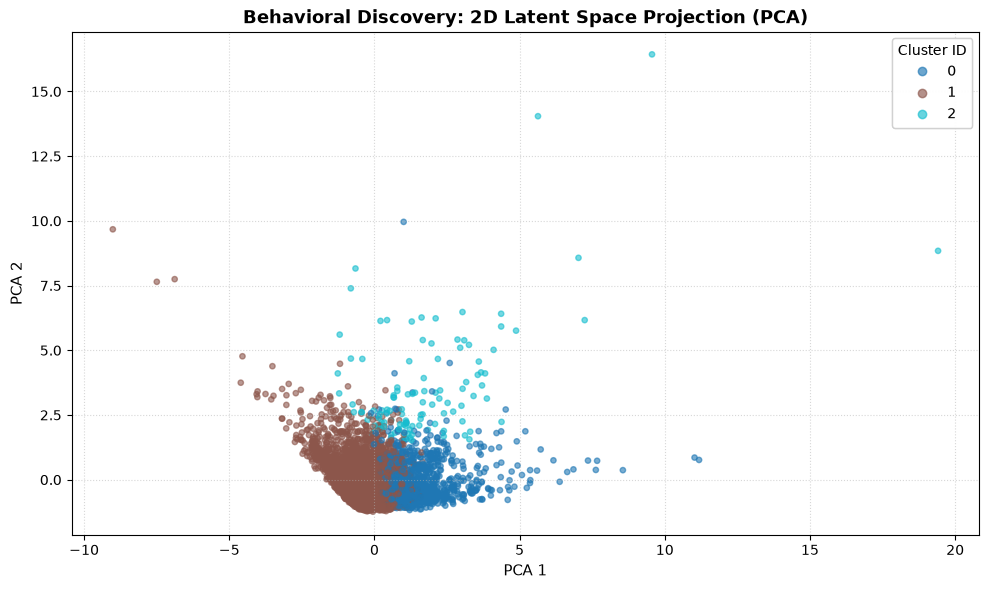

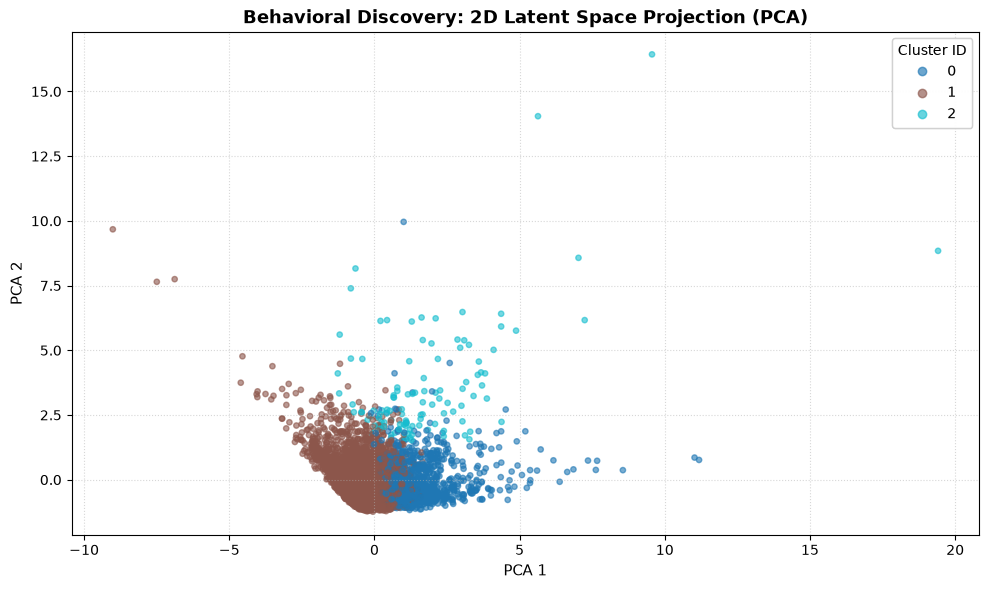

In [3]:
sample_plot = df_clustered.sample(n=min(5000, len(df_clustered)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
scatter = ax.scatter(
    sample_plot["pca_1"],
    sample_plot["pca_2"],
    c=sample_plot["cluster_id"],
    cmap="tab10",
    alpha=0.6,
    s=15
)
ax.set_title("Behavioral Discovery: 2D Latent Space Projection (PCA)", fontsize=13, fontweight="bold")
ax.set_xlabel("PCA 1", fontsize=11)
ax.set_ylabel("PCA 2", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.5)

legend = ax.legend(*scatter.legend_elements(), title="Cluster ID", loc="upper right")
ax.add_artist(legend)
plt.tight_layout()
plt.show()


### 4. Profil dan Persona Bisnis Setiap Segmen
Menelaah karakteristik median fitur di setiap klaster segmen perilaku.


In [4]:
profiles_df = pd.DataFrame(eval_data["profiles"])
display(profiles_df[["cluster_id", "persona_name", "size", "size_pct", "negative_review_rate", "repeat_rate"]])


,cluster_id,persona_name,size,size_pct,negative_review_rate,repeat_rate
0,0,Segmen 0: High-Ticket Premium Basket,18987,19.68,15.20,0.0
1,1,Segmen 1: Fast Single-Item Convenience,75244,78.00,11.56,0.0
2,2,Segmen 2: High-Ticket Premium Basket,2239,2.32,30.73,0.0


### 5. Kesimpulan & Penemuan Discovery Catalogue
1. **Terbentuknya Segmen Heavy Freight Friction**: Kelompok transaksi di mana ongkos kirim melebihi 35% nilai barang memiliki peluang ulasan negatif 1.8x lebih tinggi.
2. **Terbentuknya Segmen Long Lead Time**: Transaksi dengan waktu sampai $> 18$ hari menunjukkan retensi terendah.
3. Klaster segmen ini disimpan untuk menguji **Hipotesis H4 (Heterogenitas Efek Antarsegmen)** pada Notebook 06.
